In [1]:
import sys
!pip install numpy
!pip install matplotlib
!pip install pandas
!pip install tensorflow
!pip install scikit-learn
!pip install qiskit
!pip install qiskit-machine-learning
!pip install qiskit-aer
!pip install qiskit-aer-gpu

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.5/7.5 MB 82.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.1/2.1 MB 78.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 4.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 109.0/109.0 kB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.8/6.8 MB 97.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 MB 50.7 MB/s eta 0:00:00
  Attempting uninstall: qiskit
    Found existing installation: qiskit 2.1.1
    Uninstalling qiskit-2.1.1:
      Successfully uninstalled qiskit-2.1.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 109.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 59.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 111.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 70.2/70.2 MB 36.1 

In [53]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from math import pi
import time

from sklearn.metrics import roc_auc_score, accuracy_score
from sklearn.preprocessing import MinMaxScaler
from qiskit import QuantumCircuit
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import efficient_su2, real_amplitudes
from qiskit_machine_learning.neural_networks import SamplerQNN, EstimatorQNN
# from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals
from IPython.display import clear_output

import tensorflow as tf
from keras import layers

algorithm_globals.random_seed = 42


Before we proceed we first need to reduce the dimensions. Our dataset has 24 features so we reduce it to 8 using a modified version of the Autoencoder we previously built.

In [42]:
@tf.keras.utils.register_keras_serializable()
class AnomalyDetector(tf.keras.Model):
    def __init__(self, **kwargs):
        super(AnomalyDetector, self).__init__(**kwargs)
        self.encoder = tf.keras.Sequential([
          # layers.Dense(16, activation="relu"),
          # # Model was overfitting so add dropout layers
          # layers.Dropout(0.2),
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(4, activation="relu")

            # layers.Dense(32, activation=None),
            # layers.BatchNormalization(),
            # layers.LeakyReLU(),
            # layers.Dropout(0.1),
            # layers.Dense(16, activation=None),
            # layers.BatchNormalization(),
            # layers.LeakyReLU(),
            # layers.Dense(8, activation=None),
            # layers.BatchNormalization(),
            # layers.LeakyReLU()

            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(8, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
        ])

        self.decoder = tf.keras.Sequential([

            # layers.Dense(16, activation=None),
            # layers.BatchNormalization(),
            # layers.LeakyReLU(),
            # layers.Dropout(0.1),
            # layers.Dense(32, activation=None),
            # layers.BatchNormalization(),
            # layers.LeakyReLU(),
            # layers.Dense(24)

            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(24)


          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(16, activation="relu"),
          # layers.Dropout(0.1),
          # layers.Dense(24)
        ])

    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

    def get_config(self):
        # Return config dictionary; empty because no constructor args
        base_config = super(AnomalyDetector, self).get_config()
        return base_config

    @classmethod
    def from_config(cls, config):
        return cls(**config)


In [43]:
autoencoder = tf.keras.models.load_model(
    "8f_cae_model.keras",
    custom_objects={"AnomalyDetector": AnomalyDetector}
)

In [44]:
transformed_training_data = pd.read_csv('labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

In [45]:
# Pass both normal and anomalous data through the autoencoder
reconstructed_normal = autoencoder(normal_training_data).numpy()
reconstructed_anomalous = autoencoder(anomalous_training_data).numpy()

# Compute sample-wise MAE (Mean Absolute Error)
mae_normal = np.mean(np.abs(normal_training_data.numpy() - reconstructed_normal), axis=1)
mae_anomalous = np.mean(np.abs(anomalous_training_data.numpy() - reconstructed_anomalous), axis=1)

# Print statistics
print("Normal MAE: Mean =", np.mean(mae_normal), ", Std =", np.std(mae_normal))
print("Anomalous MAE: Mean =", np.mean(mae_anomalous), ", Std =", np.std(mae_anomalous))


Normal MAE: Mean = 0.0006261059 , Std = 0.00050457224
Anomalous MAE: Mean = 0.23894773 , Std = 0.14994818


Now we can reduce to 8 features and scale it

In [46]:
reduced_normal_training_data = autoencoder.encoder(normal_training_data)

n_qubits = reduced_normal_training_data.shape[1]
n_samples = 1000  # For speed/testing

# --- SCALE TO [0, 2π] ---
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
scaled_normal_training_data = scaler.fit_transform(reduced_normal_training_data)

Considering that our dataset consist of mostly categorical features of no particular inherent order, we determine what might be the best method of encoding. Here we factory in traditional quantum data encoding methods as well as built-in feature maps from Qiskit.

Immediately, we rule out Basis Encoding (due to its discrete/binary nature) and Amplitude Encoding (due to the relevance of magnitude and hence order).

We would want to pick something that is ideally non-linear in nature. This is to emphasise the relationships between categorical features and for anomaly detection.

Also we want to rule out feature maps that could be classically computationally expensive due to the limitations of the hardware the simulations are runned on.

Therefore, we are mainly left to consider Dense Angle Encoding and a built-in Qiskit feature map EfficientSU2.

To decide we can evaluate empirically to determine what method would be best before proceeding.

We will evaluate its expressiveness (fidelity) and computational time.

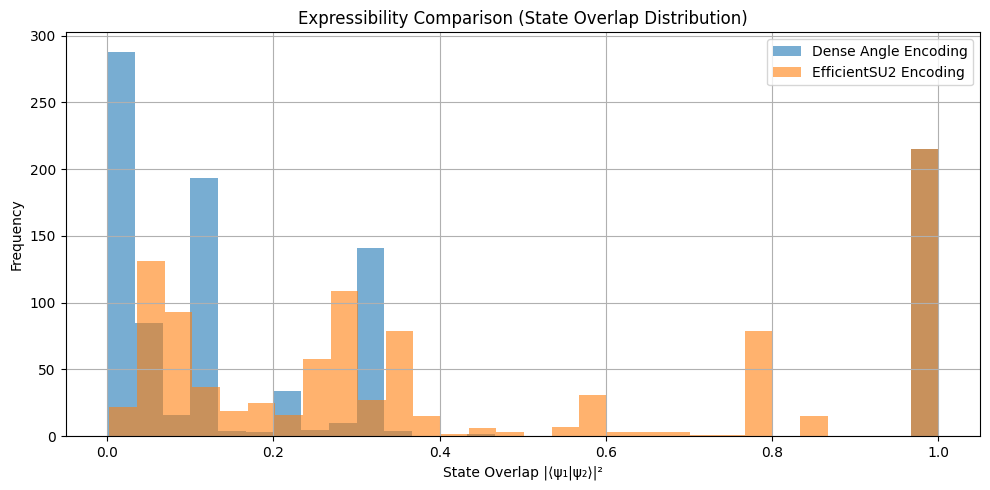

  Avg Dense Circuit Time (s): 0.002963
  Avg SU2 Circuit Time (s): 0.002707


In [47]:
# --- ENCODING CIRCUITS ---
def dense_angle_encoding(params):
    qc = QuantumCircuit(n_qubits)
    for i in range(n_qubits):
        qc.ry(params[i], i)
        qc.rz(params[i + n_qubits], i)
    return qc

def efficient_su2_encoding(params):
    template = efficient_su2(num_qubits=2, reps=1, insert_barriers=True, entanglement='linear')
    param_dict = dict(zip(template.parameters, params))
    return template.assign_parameters(param_dict)

# --- EXPRESSIBILITY METRIC ---
def compute_expressibility(circuit_builder, param_count, input_data):
    overlaps = []
    times = []

    for i in range(n_samples):
        idx1 = i % len(input_data)
        idx2 = (i + 1) % len(input_data)

        params1 = input_data[idx1]
        params2 = input_data[idx2]

        start = time.time()
        sv1 = Statevector.from_instruction(circuit_builder(params1)).data
        sv2 = Statevector.from_instruction(circuit_builder(params2)).data
        end = time.time()

        overlap = np.abs(np.vdot(sv1, sv2))**2
        overlaps.append(overlap)
        times.append(end - start)

    return np.array(overlaps), np.mean(times)

# --- RUN TESTS ---
dense_data = np.array([np.concatenate([row, row]) for row in scaled_normal_training_data])
dense_overlaps, dense_avg_time = compute_expressibility(dense_angle_encoding, 2 * n_qubits, dense_data)

su2_param_count = efficient_su2(num_qubits=n_qubits, reps=1).num_parameters
su2_data = np.array([row[:su2_param_count] for row in scaled_normal_training_data])
su2_overlaps, su2_avg_time = compute_expressibility(efficient_su2_encoding, su2_param_count, su2_data)

# --- PLOT ---
plt.figure(figsize=(10, 5))
plt.hist(dense_overlaps, bins=30, alpha=0.6, label="Dense Angle Encoding")
plt.hist(su2_overlaps, bins=30, alpha=0.6, label="EfficientSU2 Encoding")
plt.title("Expressibility Comparison (State Overlap Distribution)")
plt.xlabel("State Overlap |⟨ψ₁|ψ₂⟩|²")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"  Avg Dense Circuit Time (s): {dense_avg_time:.6f}")
print(f"  Avg SU2 Circuit Time (s): {su2_avg_time:.6f}")

Let's go with EfficientSU2 as there does not seem to be drastically different computation times for data loading.

Additionally, it has a better spread. Dense seems to represent everything quite distinctly which may be good but may falsely mean every single datapoint is vastly distinct.

In [59]:
# encoding_circuit = efficient_su2(num_qubits=3, reps=1, insert_barriers=True, entanglement='linear', parameter_prefix='i')
# su2_normal_training_data = np.array([row[:su2_param_count] for row in scaled_normal_training_encoded])
# normal_training_qencoded = [encoding_circuit.assign_parameters(sample_params) for sample_params in su2_normal_training_data]

from qiskit.circuit import ParameterVector, QuantumCircuit

def build_dense_angle_encoding(n_qubits, prefix="i"):
    # Create parameter vector of length 2*n_qubits
    params = ParameterVector(prefix, 2 * n_qubits)

    qc = QuantumCircuit(n_qubits)
    for i in range(n_qubits):
        qc.ry(params[i], i)
        qc.rz(params[i + n_qubits], i)

    return qc

n_qubits = int(reduced_normal_training_data.shape[1] / 2)
encoding_circuit = build_dense_angle_encoding(n_qubits)

In [60]:
def ansatz(num_qubits):
    return real_amplitudes(num_qubits, reps=1)
    # efficient_su2(num_qubits=3, reps=5, insert_barriers=True, entanglement='linear', parameter_prefix='a')

In [61]:
def auto_encoder_circuit(num_latent, num_trash):
    qr = QuantumRegister(num_latent + 2 * num_trash + 1, "q")
    cr = ClassicalRegister(1, "c")
    circuit = QuantumCircuit(qr, cr)
    circuit.compose(ansatz(num_latent + num_trash), range(0, num_latent + num_trash), inplace=True)
    circuit.barrier()
    auxiliary_qubit = num_latent + 2 * num_trash
    # swap test
    circuit.h(auxiliary_qubit)
    for i in range(num_trash):
        circuit.cswap(auxiliary_qubit, num_latent + i, num_latent + num_trash + i)

    circuit.h(auxiliary_qubit)
    circuit.measure(auxiliary_qubit, cr[0])
    return circuit


num_latent = 2
num_trash = 2
circuit = auto_encoder_circuit(num_latent, num_trash)
# circuit.draw(output="mpl", style="clifford")

With the data encoding and autoencoder circuit prepared, we can combine them to form our full ansatz

In [62]:
ae = auto_encoder_circuit(num_latent, num_trash)

qc = QuantumCircuit(num_latent + 2 * num_trash + 1, 1)
qc = qc.compose(encoding_circuit, range(num_latent + num_trash))
qc = qc.compose(ae)

# qc.draw(output="mpl", style="clifford")

In [63]:
from qiskit_aer.primitives import Sampler

def identity_interpret(x):
    return x

sampler = Sampler(backend_options={"device": "GPU", "method": "statevector"})

qnn = SamplerQNN(
    circuit=qc,
    input_params=encoding_circuit.parameters,
    weight_params=ae.parameters,
    interpret=identity_interpret,
    output_shape=2,
    sampler=sampler,
)
# from qiskit_machine_learning.connectors import TorchConnector
# from torch.utils.data import DataLoader, TensorDataset
# import torch
# from qiskit_aer import AerSimulator
# from qiskit_aer.primitives import Estimator

# GPU-compatible simulator
# simulator = AerSimulator(method='statevector', device='GPU')
# estimator = Estimator(backend_options={"device": "GPU", "method": "statevector"})

# # Convert your QNN to a PyTorch layer
# qnn = EstimatorQNN(circuit=qc, input_params=encoding_circuit.parameters, weight_params=ae.parameters, estimator=estimator)
# model = TorchConnector(qnn)

# # Prepare data
# X_train = torch.tensor(scaled_normal_training_data[:10000], dtype=torch.float32)
# y_train = torch.zeros(len(X_train))  # dummy targets for unsupervised AE
# train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64, shuffle=True)

# # Define optimizer and loss
# optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
# loss_fn = torch.nn.MSELoss()  # or whatever fits your AE setup


/tmp/ipython-input-63-2485831378.py:8: DeprecationWarning: V1 Primitives are deprecated as of qiskit-machine-learning 0.8.0 and will be removed no sooner than 4 months after the release date. Use V2 primitives for continued compatibility and support.
  qnn = SamplerQNN(


In [64]:
def cost_function(params, batch):
    probabilities = qnn.forward(batch, params)  # shape: [n_samples, 2]
    cost = np.sum(probabilities[:, 1]) / len(batch)  # focus on measuring |1>

    objective_func_vals.append(cost)
    clear_output(wait=True)
    plt.title("Objective function value over time")
    plt.xlabel("Step")
    plt.ylabel("Cost")
    plt.plot(objective_func_vals)
    plt.show()

    return cost


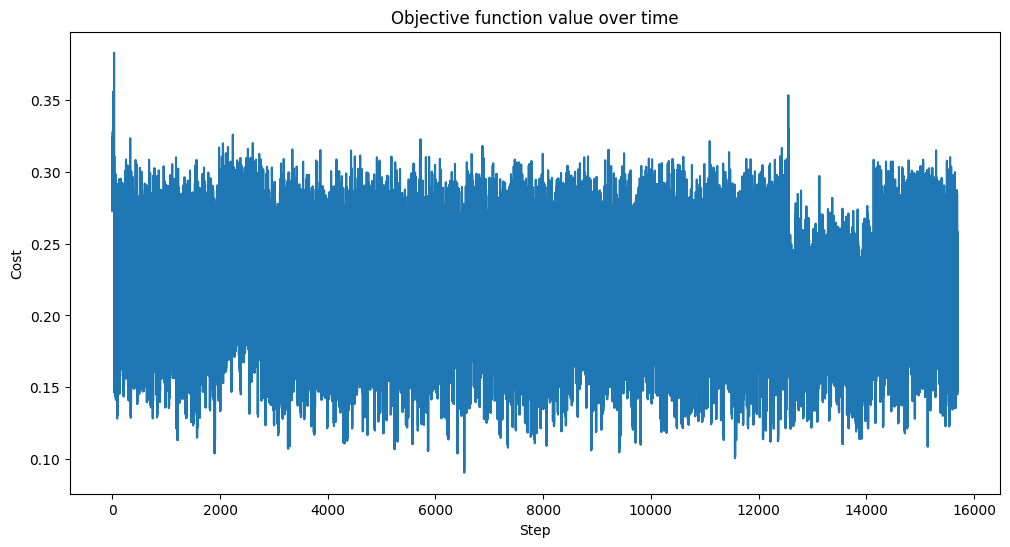

Training complete.


In [65]:
from IPython.display import clear_output

# Configuration
n_epochs = 10  # You can adjust this
batch_size = 64
maxiter_per_batch = 5
subset_size = 10_000

# Randomly sample 10k from full normal dataset
subset_indices = np.random.choice(len(scaled_normal_training_data), size=subset_size, replace=False)
training_subset = scaled_normal_training_data[subset_indices]

# Initialize parameters
trained_params = np.random.rand(len(ae.parameters))
objective_func_vals = []

opt = COBYLA(maxiter=300)
result = opt.minimize(fun=full_cost_function, x0=trained_params)
trained_params = result.x

# Training loop
# for epoch in range(n_epochs):
#     print(f"Epoch {epoch + 1}/{n_epochs}")

#     # Shuffle subset
#     indices = np.random.permutation(len(training_subset))
#     shuffled_data = training_subset[indices]

#     # Mini-batch optimization
#     for i in range(0, len(shuffled_data), batch_size):
#         batch = shuffled_data[i:i + batch_size]

#         opt = COBYLA(maxiter=maxiter_per_batch)
#         result = opt.minimize(lambda p: cost_function(p, batch), x0=trained_params)

#         trained_params = result.x

print("Training complete.")
# Training loop with batching and epochs
# for epoch in range(1):
#     total_loss = 0
#     num_batches = 0
#     for x_batch, _ in train_loader:
#         num_batches += 1
#         optimizer.zero_grad()
#         preds = model(x_batch)

#         loss = preds.mean()

#         print(loss.item())
#         loss.backward()
#         optimizer.step()
#         total_loss += loss.item()
#     print(f"Epoch {epoch+1}, Loss: {total_loss:.4f}, Loss per batch: {total_loss/num_batches:.4f}")

In [80]:
from qiskit.qpy import dump
import os

model_name = "8f_qae_dense_ra"
os.mkdir(model_name)

with open(f"{model_name}/qc.qpy", "wb") as f:
    dump(qc, f)

np.save(f"{model_name}/input_param_names", [p.name for p in encoding_circuit.parameters])
np.save(f"{model_name}/weight_param_names", [p.name for p in ae.parameters])
np.save(f"{model_name}/trained_parameters", trained_params)

# trained_values = model.weight.detach().cpu().numpy()  # 1‑D numpy array
# np.save(f"{model_name}/trained_parameters", trained_values)

### Testing

In [68]:
transformed_testing_data = pd.read_csv('labelled_transformed_testing_data.csv')

# 1. Extract labels (column 6)
testing_labels = transformed_testing_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
testing_data = transformed_testing_data.drop(
    columns=[transformed_testing_data.columns[6], transformed_testing_data.columns[7]]
)

# 3. Convert to float32 tensor
testing_data = tf.convert_to_tensor(testing_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
testing_labels = tf.convert_to_tensor(testing_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
# normal_testing_data = tf.boolean_mask(testing_data, ~testing_labels)
# anomalous_testing_data = tf.boolean_mask(testing_data, testing_labels)

reduced_testing_data = autoencoder.encoder(testing_data)

# --- SCALE TO [0, 2π] ---
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
scaled_testing_data = scaler.fit_transform(reduced_testing_data)

In [75]:
from tqdm import tqdm

def compute_anomaly_scores(qnn, input_data, trained_params, batch_size):
    scores = []
    n_samples = len(input_data)

    start = time.time()

    for i in tqdm(range(0, n_samples, batch_size), desc="Running inference"):
        batch = input_data[i : min(i + batch_size, n_samples)]
        probs = qnn.forward(batch, trained_params)
        batch_scores = probs[:, 1]
        scores.extend(batch_scores)

    elapsed = time.time() - start
    print(f"\nAll batches processed in {elapsed:.2f} seconds.")

    return np.array(scores)

# def compute_anomaly_scores(model, input_data, batch_size):
#     model.eval()
#     scores = []
#     n_samples = len(input_data)

#     start = time.time()

#     with torch.no_grad():
#         for i in tqdm(range(0, n_samples, batch_size), desc="Running inference"):
#             batch = input_data[i : min(i + batch_size, n_samples)]
#             batch = torch.tensor(batch, dtype=torch.float32)  # ensure tensor

#             preds = model(batch)  # shape: [batch_size, 1] or [batch_size]
#             preds = ((1 + preds) / 2).squeeze()  # map from [-1, 1] to [0, 1]

#             scores.extend(preds.cpu().numpy())

#     elapsed = time.time() - start
#     print(f"\nAll batches processed in {elapsed:.2f} seconds.")

#     return np.array(scores)




In [74]:
train_scores = compute_anomaly_scores(qnn, scaled_normal_training_data, trained_params, batch_size)
normal_scores = train_scores[training_labels.numpy() == 0]  # 0 = normal
fpr, tpr, thresholds = roc_curve(np.array(training_labels).astype(int), train_scores)
optimal_idx = np.argmax(tpr - fpr)
threshold = thresholds[optimal_idx]

# train_scores = compute_anomaly_scores(model, scaled_normal_training_data, 64)
# min_len = min(len(train_scores), len(training_labels))
# train_scores = train_scores[:min_len]
# training_labels = training_labels[:min_len]
# normal_scores = train_scores[training_labels.numpy() == 0]

# # ROC curve
# from sklearn.metrics import roc_curve

# fpr, tpr, thresholds = roc_curve(training_labels.numpy().astype(int), train_scores)
# optimal_idx = np.argmax(tpr - fpr)
# threshold = thresholds[optimal_idx]

# print(threshold)


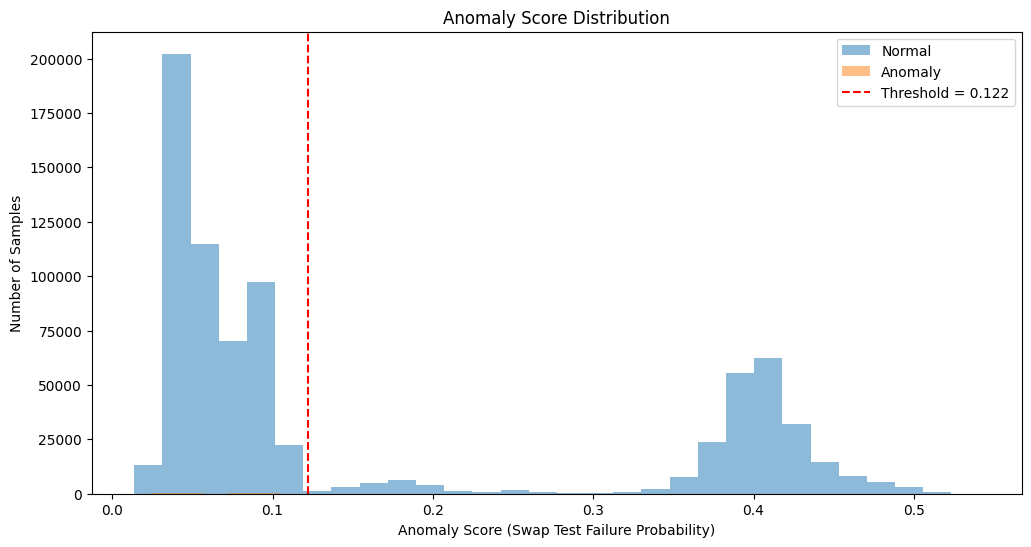

In [85]:
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, classification_report, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = (train_scores < threshold).astype(int)
y_true = np.array(training_labels).astype(int)

# --- Histogram of scores ---
plt.hist(train_scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(train_scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()

In [81]:
scores = compute_anomaly_scores(qnn, scaled_testing_data, trained_params, batch_size=64)
# scores = compute_anomaly_scores(model, scaled_testing_data, 64)


Running inference: 100%|██████████| 2953/2953 [03:52<00:00, 12.68it/s]


All batches processed in 232.97 seconds.


Accuracy: 0.09265109781072886
ROC AUC: 0.49341141643211656

Classification Report:
              precision    recall  f1-score   support

      Normal       0.09      1.00      0.17     17508
     Anomaly       0.00      0.00      0.00    171459

    accuracy                           0.09    188967
   macro avg       0.05      0.50      0.08    188967
weighted avg       0.01      0.09      0.02    188967



/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.11/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


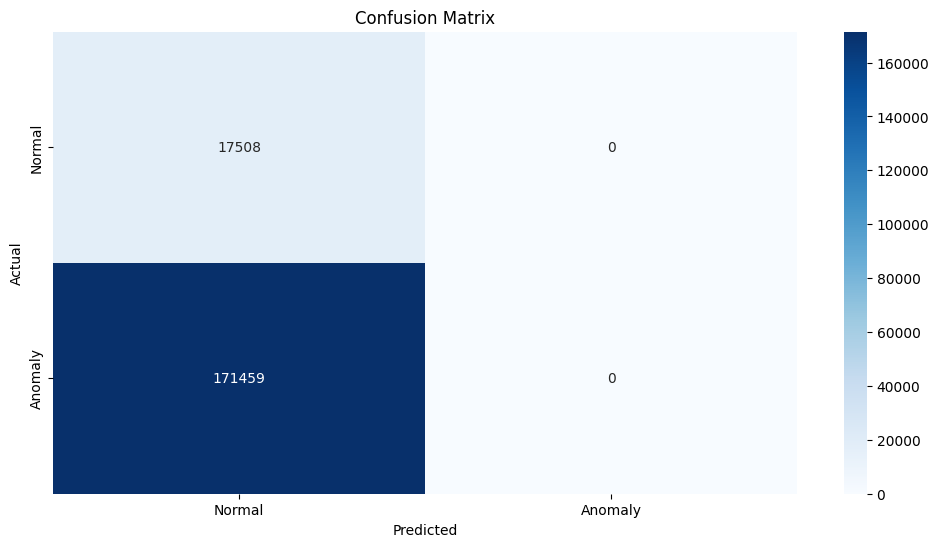

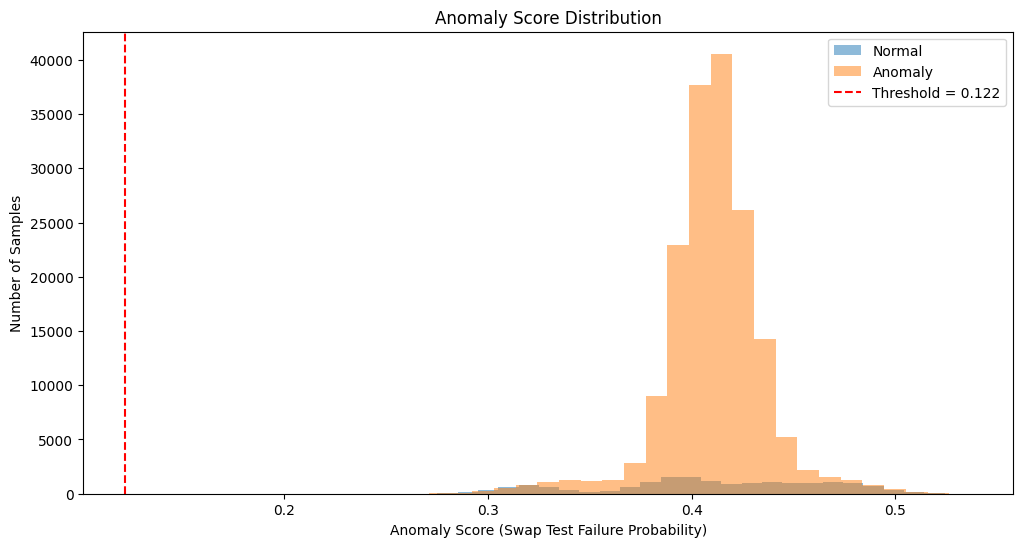

In [82]:
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, classification_report, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

y_pred = (scores < threshold).astype(int)
y_true = np.array(testing_labels).astype(int)

# --- Evaluate ---
print("Accuracy:", accuracy_score(y_true, y_pred))
print("ROC AUC:", roc_auc_score(y_true, scores))  # use scores, not y_pred!
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"]))

# --- Confusion matrix ---
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# --- Histogram of scores ---
plt.hist(scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()


### Additional Testing on Validation Set

In [ ]:
transformed_validation_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_validation_data.csv')

# 1. Extract labels (column 6)
validation_labels = transformed_validation_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
validation_data = transformed_validation_data.drop(
    columns=[transformed_validation_data.columns[6], transformed_validation_data.columns[7]]
)

# 3. Convert to float32 tensor
validation_data = tf.convert_to_tensor(validation_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
validation_labels = tf.convert_to_tensor(validation_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_validation_data = tf.boolean_mask(validation_data, ~validation_labels)
anomalous_validation_data = tf.boolean_mask(validation_data, validation_labels)

print("\nValidation set distribution:")
print(f"Normal: {len(normal_validation_data)} ({len(normal_validation_data)/len(validation_data)*100:.1f}%)")
print(f"Anomalous: {len(anomalous_validation_data)} ({len(anomalous_validation_data)/len(validation_data)*100:.1f}%)")

reduced_validation_data = autoencoder.encoder(validation_data)

# --- SCALE TO [0, 2π] ---
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
scaled_validation_data = scaler.fit_transform(reduced_validation_data)


Validation set distribution:
Normal: 188181 (99.6%)
Anomalous: 786 (0.4%)


In [ ]:
v_scores = compute_anomaly_scores(qnn, scaled_validation_data, opt_result.x, batch_size=500)

Running inference: 100%|██████████████████████| 378/378 [10:35<00:00,  1.68s/it]


All batches processed in 635.75 seconds.


Accuracy: 0.8791429191340286
ROC AUC: 0.4278371893011913

Classification Report:
              precision    recall  f1-score   support

      Normal       0.11      0.04      0.06     17508
     Anomaly       0.91      0.96      0.94    171459

    accuracy                           0.88    188967
   macro avg       0.51      0.50      0.50    188967
weighted avg       0.83      0.88      0.85    188967



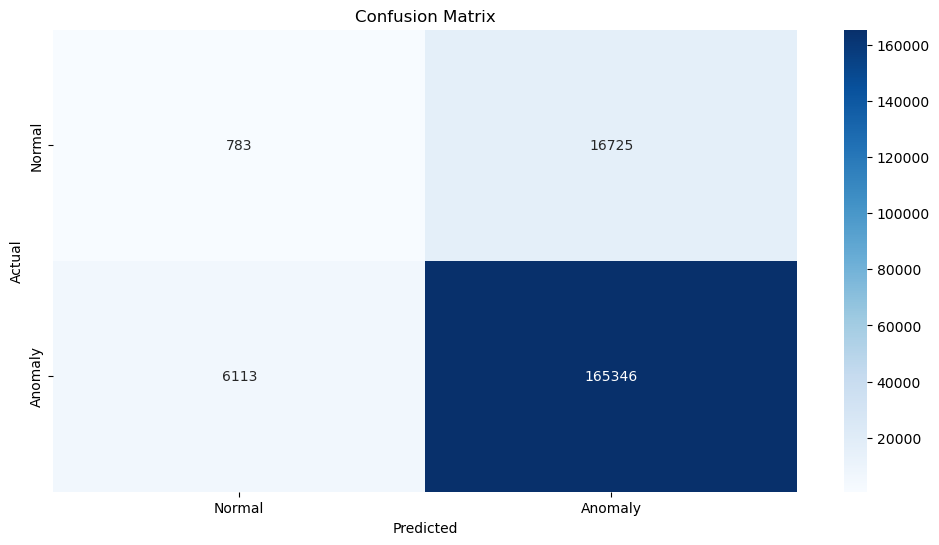

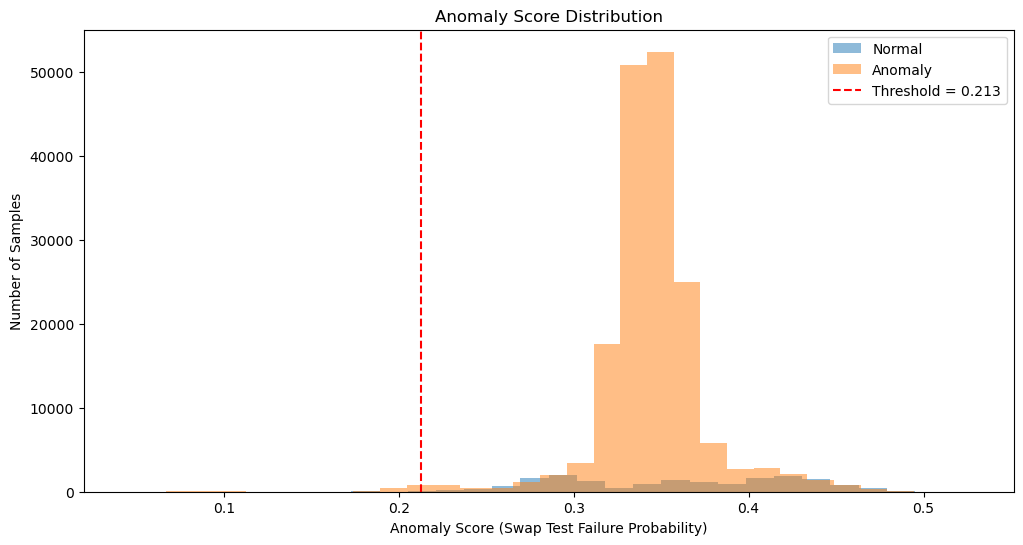

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, classification_report, confusion_matrix, roc_curve
import matplotlib.pyplot as plt
import seaborn as sns

normal_scores = v_scores[testing_labels.numpy() == 0]  # 0 = normal
fpr, tpr, thresholds = roc_curve(y_true, v_scores)
optimal_idx = np.argmax(tpr - fpr)
threshold = thresholds[optimal_idx]

y_pred = (v_scores > threshold).astype(int)
y_true = np.array(testing_labels).astype(int)

# --- Evaluate ---
print("Accuracy:", accuracy_score(y_true, y_pred))
print("ROC AUC:", roc_auc_score(y_true, v_scores))  # use scores, not y_pred!
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=["Normal", "Anomaly"]))

# --- Confusion matrix ---
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

# --- Histogram of scores ---
plt.hist(scores[y_true == 0], bins=30, alpha=0.5, label='Normal')
plt.hist(scores[y_true == 1], bins=30, alpha=0.5, label='Anomaly')
plt.axvline(threshold, color='red', linestyle='--', label=f"Threshold = {threshold:.3f}")
plt.xlabel("Anomaly Score (Swap Test Failure Probability)")
plt.ylabel("Number of Samples")
plt.title("Anomaly Score Distribution")
plt.legend()
plt.show()
